# Лабораторна робота №2. Статистичне навчання за Big Data Time Series
Виконано групи вимог 1 і 2 (ІІ рівень): вибір моделі, МНК, екстраполяція, моделювання та очищення аномальних вимірів.

## 1. Вхідні дані (властивості з Лр1)
Нормальна похибка N(0, 0.1).

In [1]:
def rando_norm (dm, dsig, iter):
    S = np.random.normal(dm, dsig, iter)
    mS = np.mean(S)
    dS = np.var(S)
    scvS = mt.sqrt(dS)
    print('------- Статистичні характеристики НОРМАЛЬНОГО закону розподілу ВВ -----')
    print('Матиматичне сподівання ВВ=', mS)
    print('Дисперсія ВВ =', dS)
    print('СКВ ВВ=', scvS)

    print('------------------------------------------------------------------------')
    plt.hist(S, bins=8, facecolor="blue", alpha=0.5, edgecolor="black")
    plt.show()
    return S

------- Статистичні характеристики НОРМАЛЬНОГО закону розподілу ВВ -----
Матиматичне сподівання ВВ= 0.0005490876931500997
Дисперсія ВВ = 0.009779068944985234
СКВ ВВ= 0.09888917506474222
------------------------------------------------------------------------


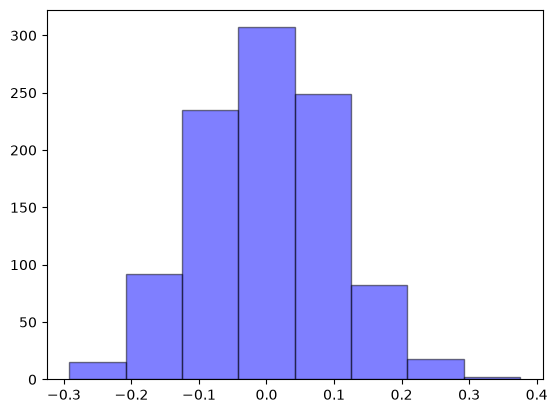

In [2]:
import numpy as np
import math as mt
import matplotlib.pyplot as plt

N = 1000
x = range(N)

normal_sample = rando_norm(0, 0.1, N)

Квадратичний тренд і адитивна модель: тренд + нормальний шум.

In [3]:
def square_model(n):
    S0=np.zeros(n)
    for i in range(n):
        S0[i]=(0.000001*i*i)
    return S0
square_y = square_model(N)

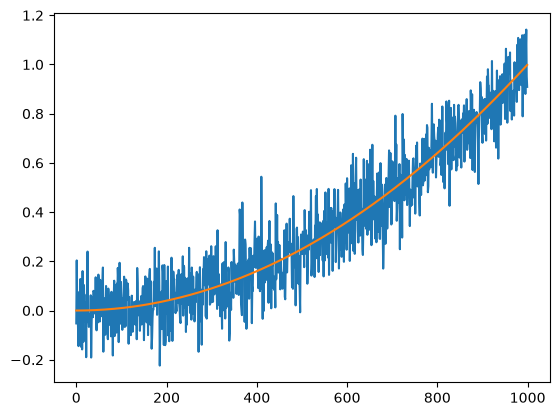

-----------Характеристики:------------
Мат. сподівання: 0.33338258769315005
Дисперсія: 0.09586258715188384
Середньоквадратичне відхилення: 0.30961683925762795
---------------------------|-----------


In [4]:
additive_square_normal = [x + y for x, y in zip(normal_sample, square_y)]

def plot_additive(additive_model, ideal_model):
    plt.plot(x, additive_model)
    plt.plot(x, ideal_model)
    plt.show()
    mean = np.mean(additive_model)
    std = np.std(additive_model)
    var = np.var(additive_model)
    print("-----------Характеристики:------------")
    print("Мат. сподівання: " + str(mean))
    print("Дисперсія: " + str(var))
    print("Середньоквадратичне відхилення: " + str(std))
    print("---------------------------|-----------")
    
plot_additive(additive_square_normal, square_y)

## 2. Вибір моделі: метод ліктя
Показник якості — MSE. Перебираємо степінь полінома від 1 до 6 і шукаємо точку, після якої MSE перестає суттєво зменшуватися.

In [5]:
import numpy as np
import matplotlib.pyplot as plt

def plot_elbow(SL, t=None, max_degree=6):
    n = len(SL)
    if t is None:
        t = np.arange(n)

    res = []
    for m in range(1, max_degree + 1):
        coefs = np.polyfit(t, SL, m)
        fitted = np.polyval(coefs, t)
        mse = np.sum((SL - fitted) ** 2) / n
        res.append(mse)

    plt.plot(range(1, max_degree + 1), res, marker='o')
    plt.xlabel("Degree of polynomial")
    plt.ylabel("MSE")
    plt.title("Elbow method")
    plt.grid(True)
    plt.show()

    return res

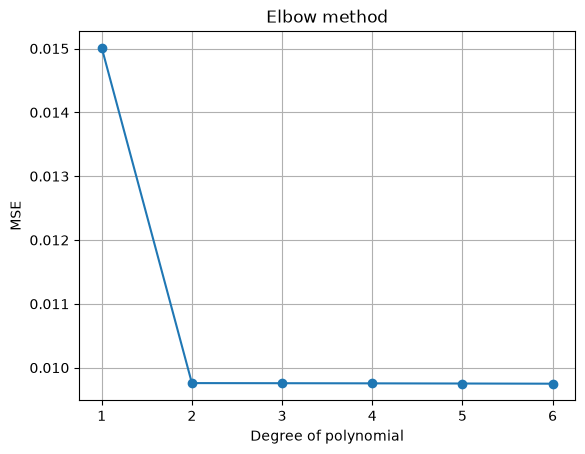

[np.float64(0.015013114597502937),
 np.float64(0.009758510405862616),
 np.float64(0.009756693532493973),
 np.float64(0.009754503078063274),
 np.float64(0.00975187902937654),
 np.float64(0.00974901275514477)]

In [6]:
plot_elbow(additive_square_normal)

Після 2-го степеня MSE майже не змінюється (0.0150 → 0.0098 → 0.0098), тому обираємо квадратичну модель.

## 3. МНК: поліноміальна регресія 2-го степеня
Матричний розв'язок: C = (FᵀF)⁻¹FᵀY.

In [7]:
def LSM(S0):

    iter = len(S0)
    Yin = np.zeros((iter, 1))
    F = np.ones((iter, 3))

    for i in range(iter):  # формування структури вхідних матриць МНК
        Yin[i, 0] = float(S0[i])  # формування матриці вхідних даних
        F[i, 1] = float(i)
        F[i, 2] = float(i * i)

    FT = F.T
    FFT = FT.dot(F)
    FFTI = np.linalg.inv(FFT)
    FFTIFT = FFTI.dot(FT)
    C = FFTIFT.dot(Yin)
    Yout = F.dot(C)

    print('Регресійна модель:')
    print('y(t) = ', C[0,0], ' + ', C[1,0], ' * t', ' + ', C[2,0], ' * t^2')

    return Yout, C[0,0], C[1,0], C[2,0]


In [8]:
yout, c1, c2, c3 = LSM(additive_square_normal)

Регресійна модель:
y(t) =  0.0029867910778522263  +  1.3417420838609482e-05  * t  +  9.72539708011398e-07  * t^2


Порівняння навченої моделі (синій) з ідеальним трендом (помаранчевий).

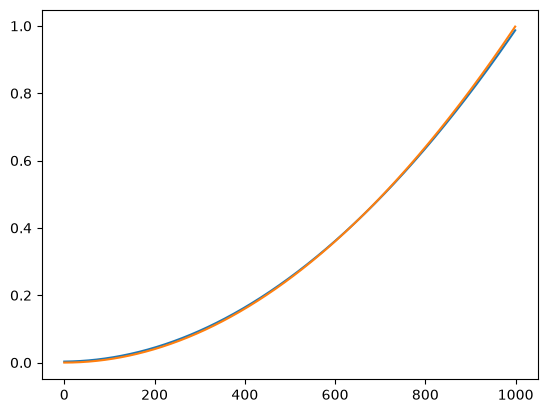

In [9]:
plt.plot(yout)
plt.plot(square_y)
plt.show()

## 4. Екстраполяція на 0.5 інтервалу спостереження
Прогнозуємо ще 500 точок за навченою моделлю (червоний).

In [10]:
def poly_model_params(t, c1, c2, c3):
    return  c1  +  c2  * t  +  c3  * t ** 2
poly_model = lambda t : poly_model_params(t, c1, c2, c3)

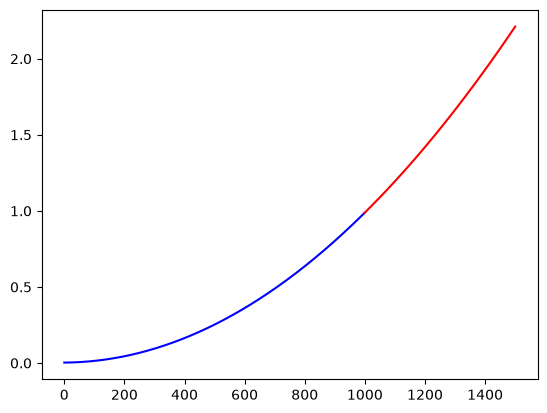

In [18]:
n = 1000
extrapolated_range = range(n, int(1.5*n+1))
extrapolated = [poly_model(t) for t in extrapolated_range]
plt.plot(np.arange(len(yout)), yout, color="blue")
plt.plot(extrapolated_range, extrapolated, color="red")
plt.show()

## 5. Модель аномальних вимірів
Додаємо 20 аномальних значень у випадкові позиції.

In [12]:
def Model_NORM_AV(S0, SV, nAV, Q_AV, dm,  dsig):

    SV_AV = np.copy(SV)
    SSAV = np.random.normal(dm, (Q_AV * dsig), nAV)  # аномальна випадкова похибка з нормальним законом

    SAV = np.random.default_rng().integers(low=0, high = 1000, size = nAV)
    for i in range(nAV):
        k = int(SAV[i])
        SV_AV[k] = S0[k] + SSAV[i]        # аномальні вимірів з рівномірно розподіленими номерами

    return SV_AV


In [13]:
SV_AV = Model_NORM_AV(square_y, additive_square_normal, 20, 0.6, 0, 1)

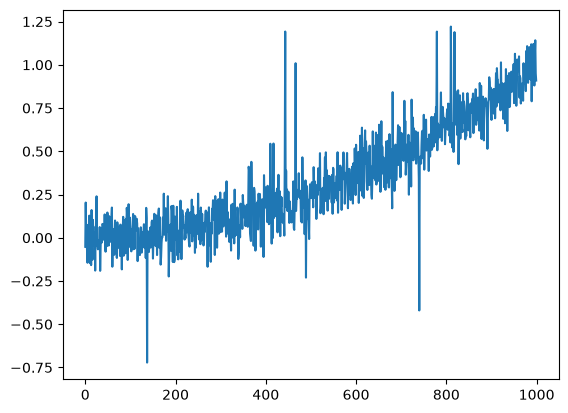

In [14]:
plt.plot(SV_AV)
plt.show()

## 6. Очищення від аномалій ковзним вікном
Якщо СКВ у вікні перевищує еталонне СКВ у Q разів, останнє значення вікна замінюється медіаною вікна.

In [15]:
def Sliding_Window_AV_Detect_medium(S0, n_Wind, Q):
    iter = len(S0)
    j_Wind=mt.ceil(iter-n_Wind)+1
    S0_Wind=np.zeros((n_Wind))

    j = 0
    for i in range(n_Wind):
        l = (j + i)
        S0_Wind[i] = S0[l]
        dS_standart = np.var(S0_Wind)
        scvS_standart = mt.sqrt(dS_standart)


    for j in range(j_Wind):
        for i in range(n_Wind):
            l=(j+i)
            S0_Wind[i] = S0[l]

        mS = np.median(S0_Wind)
        dS = np.var(S0_Wind)
        scvS = mt.sqrt(dS)

        if scvS > (Q * scvS_standart):
            S0[l] = mS

    return S0

In [16]:
cleaned = Sliding_Window_AV_Detect_medium(SV_AV, 50, 1.1)

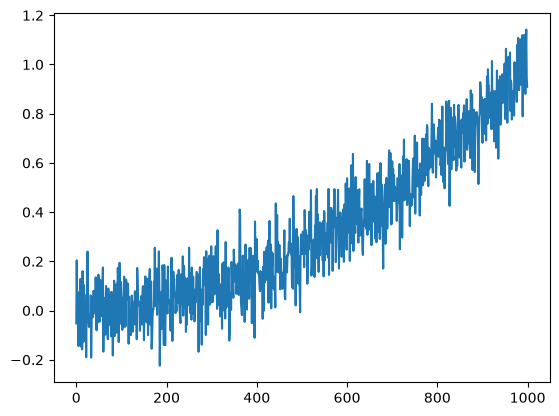

In [17]:
plt.plot(cleaned)
plt.show()

## Висновки
Метод ліктя показав, що після 2-го степеня MSE практично не зменшується, тому квадратична модель оптимальна й відповідає справжньому закону тренду. Коефіцієнт при t² у МНК-моделі (0.97·10⁻⁶) майже збігається з ідеальним (1·10⁻⁶), і навчена модель на графіку накладається на ідеальний тренд. Екстраполяція на 0.5 інтервалу продовжує параболу і коректна, поки характер процесу не змінюється. Алгоритм ковзного вікна прибрав усі помітні аномальні викиди, і очищений ряд візуально відповідає вихідній адитивній моделі.